In [18]:
import pandas as pd

df = pd.read_csv("../data/employee_workload_dataset_2000x30.csv")

In [19]:
print(f"cek 5 data teratas \n {df.head()} \n")
print(f"cek ukuran dataset \n {df.shape} \n")
print(f"cek nama kolom \n {df.columns} \n")
print(f"cek info datset \n {df.info()} \n")
print(f"cek statistik \n {df.describe()} \n")
print(f"cek missing value \n {df.isnull().sum()} \n")
print(f"cek data duplilkat \n {df.duplicated().sum()} \n")



cek 5 data teratas 
   employee_id           department       division position_level  \
0    EMP00001                 Umum       Logistik     Supervisor   
1    EMP00002            Pelayanan   Front Office   Senior Staff   
2    EMP00003                 Umum       Logistik          Staff   
3    EMP00004  Teknologi Informasi  Infrastruktur   Senior Staff   
4    EMP00005          Kepegawaian  Kesejahteraan   Junior Staff   

  employment_type  years_experience  age  working_days  working_hours  \
0           Tetap               2.3   31            20          158.6   
1         Kontrak               6.0   24            23          193.5   
2         Kontrak               1.2   29            20          162.8   
3           Tetap               6.4   25            21          158.2   
4           Tetap               1.7   27            20          163.3   

   overtime_hours  ...  leave_days  average_processing_time  error_count  \
0            55.0  ...           1                     

In [20]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 2000 entries, 0 to 1999
Data columns (total 30 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   employee_id              2000 non-null   str    
 1   department               2000 non-null   str    
 2   division                 2000 non-null   str    
 3   position_level           2000 non-null   str    
 4   employment_type          2000 non-null   str    
 5   years_experience         2000 non-null   float64
 6   age                      2000 non-null   int64  
 7   working_days             2000 non-null   int64  
 8   working_hours            2000 non-null   float64
 9   overtime_hours           2000 non-null   float64
 10  incoming_documents       2000 non-null   int64  
 11  processed_documents      2000 non-null   int64  
 12  pending_documents        2000 non-null   int64  
 13  service_requests         2000 non-null   int64  
 14  completed_requests       2000 non-n

In [ ]:
df["department"].value_counts()

In [9]:
df["division"].value_counts()

division
Layanan Publik      132
Front Office        119
Tata Usaha          118
Rumah Tangga        117
Arsip               117
Kesejahteraan       116
Logistik            114
Persuratan          114
Pengaduan           107
Rekrutmen           103
Administrasi SDM    101
Perbendaharaan       99
Akuntansi            87
Operasional          84
Anggaran             80
Evaluasi             77
Program              69
Aplikasi             66
Pelaporan            63
Helpdesk             59
Infrastruktur        58
Name: count, dtype: int64

In [10]:
df["position_level"].value_counts()

position_level
Staff           792
Senior Staff    539
Supervisor      308
Junior Staff    239
Manager         122
Name: count, dtype: int64

In [11]:
df["employment_type"].value_counts()

employment_type
Tetap          1321
Kontrak         505
Outsourcing     174
Name: count, dtype: int64

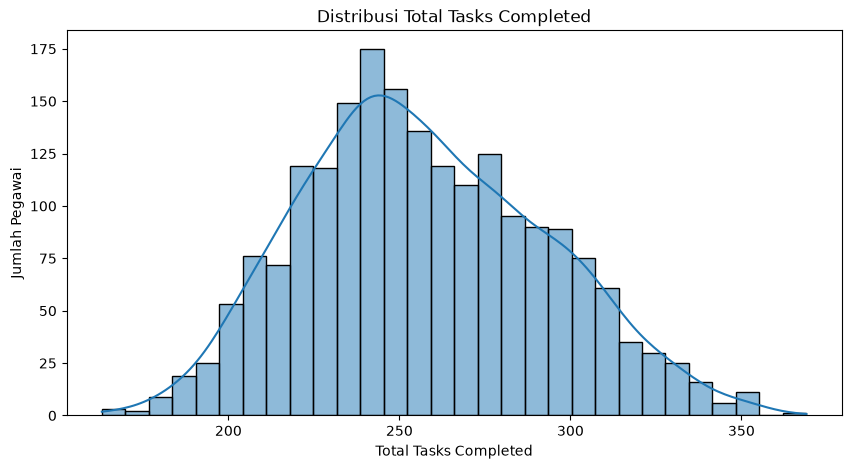

In [12]:
plt.figure(figsize=(10, 5))

sns.histplot(
    df["total_tasks_completed"],
    bins=30,
    kde=True
)

plt.title("Distribusi Total Tasks Completed")
plt.xlabel("Total Tasks Completed")
plt.ylabel("Jumlah Pegawai")

plt.show()

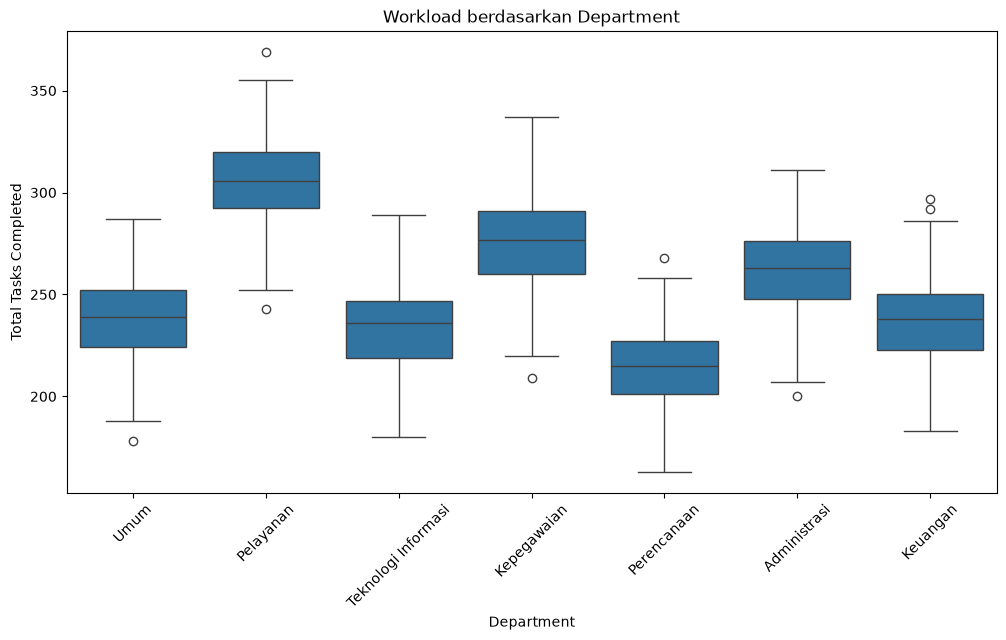

In [13]:
plt.figure(figsize=(12, 6))

sns.boxplot(
    data=df,
    x="department",
    y="total_tasks_completed"
)

plt.xticks(rotation=45)
plt.title("Workload berdasarkan Department")
plt.xlabel("Department")
plt.ylabel("Total Tasks Completed")

plt.show()

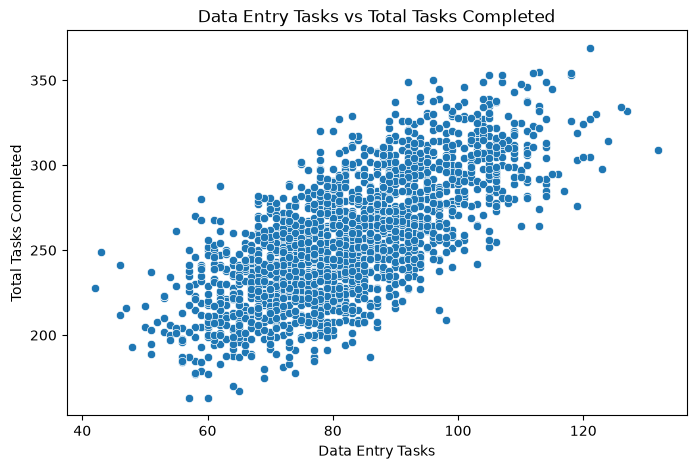

In [14]:
plt.figure(figsize=(8, 5))

sns.scatterplot(
    data=df,
    x="data_entry_tasks",
    y="total_tasks_completed"
)

plt.title("Data Entry Tasks vs Total Tasks Completed")
plt.xlabel("Data Entry Tasks")
plt.ylabel("Total Tasks Completed")

plt.show()

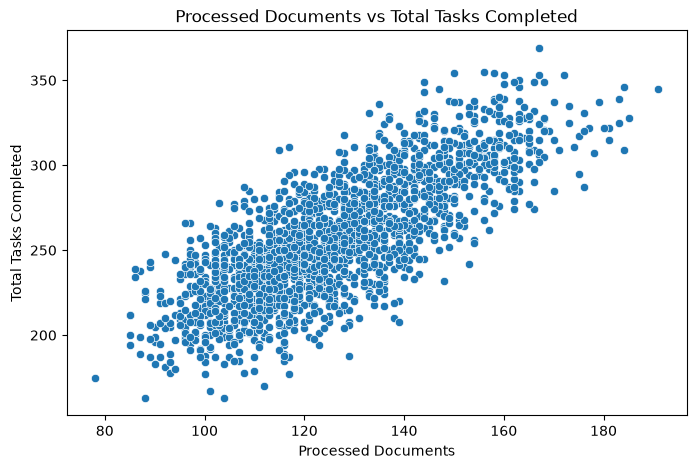

In [15]:
plt.figure(figsize=(8, 5))

sns.scatterplot(
    data=df,
    x="processed_documents",
    y="total_tasks_completed"
)

plt.title("Processed Documents vs Total Tasks Completed")
plt.xlabel("Processed Documents")
plt.ylabel("Total Tasks Completed")

plt.show()

In [16]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

numeric_df = df.select_dtypes(include=np.number)

correlation = numeric_df.corr()

correlation["total_tasks_completed"].sort_values(
    ascending=False
)

total_tasks_completed      1.000000
incoming_documents         0.781017
processed_documents        0.780549
data_entry_tasks           0.713418
completed_requests         0.709414
service_requests           0.709195
verification_tasks         0.650389
report_tasks               0.466329
productivity_score         0.174156
overtime_hours             0.114633
automation_level           0.100594
system_usage_hours         0.089261
working_hours              0.018763
working_days               0.016330
leave_days                 0.015594
training_hours            -0.005433
age                       -0.011984
pending_documents         -0.017002
years_experience          -0.039924
meeting_hours             -0.056547
customer_complaints       -0.063623
task_complexity           -0.068573
remote_work_days          -0.069964
average_processing_time   -0.072965
error_count               -0.183123
Name: total_tasks_completed, dtype: float64

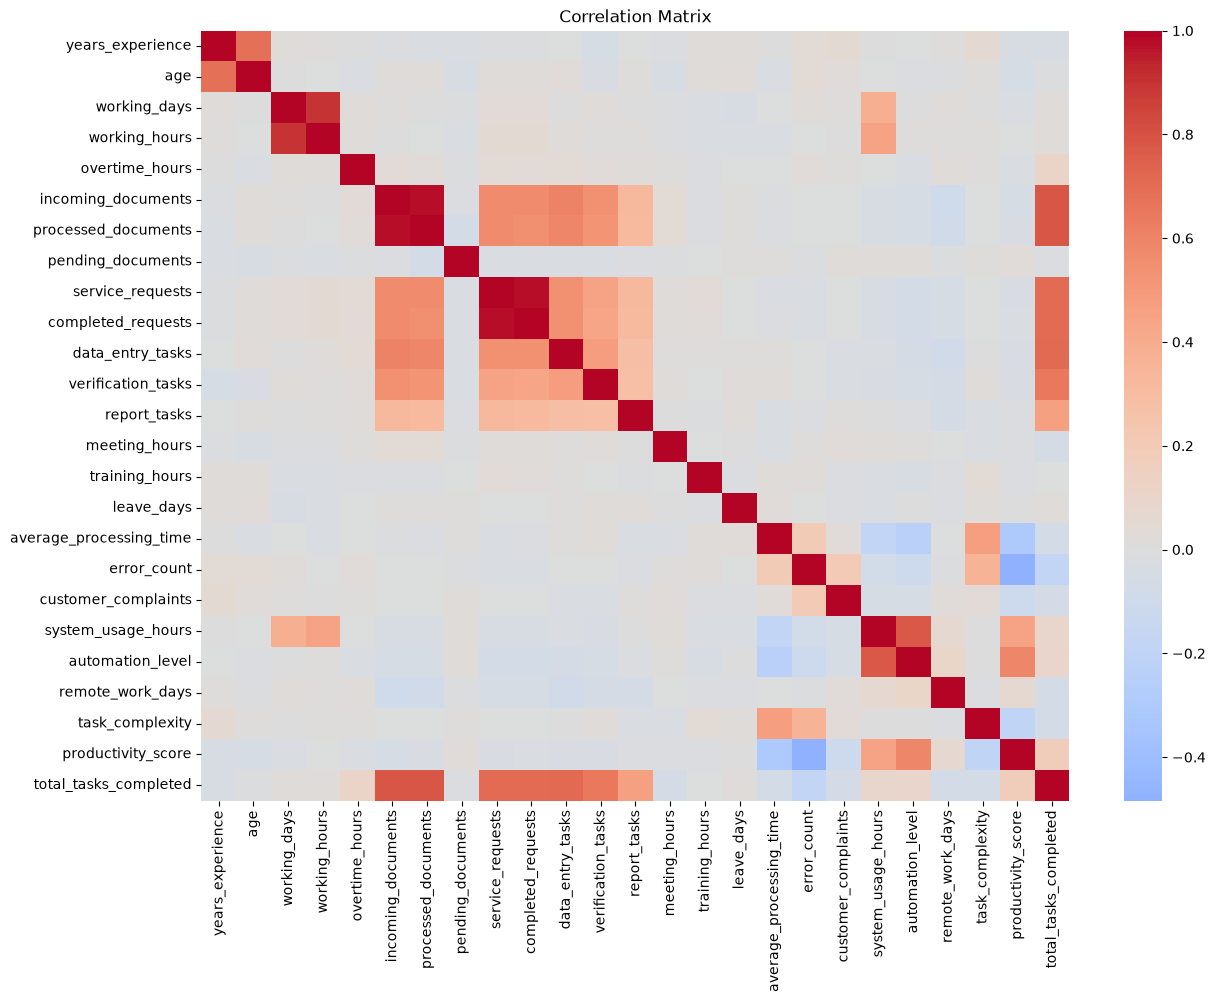

In [17]:
plt.figure(figsize=(14, 10))

sns.heatmap(
    correlation,
    cmap="coolwarm",
    center=0
)

plt.title("Correlation Matrix")

plt.show()

In [ ]:
# Cek missing value

missing_report = pd.DataFrame({
    "missing_count": df.isnull().sum(),
    "missing_percentage": (
        df.isnull().sum() / len(df) * 100
    )
})

missing_report = missing_report[
    missing_report["missing_count"] > 0
].sort_values(
    by="missing_percentage",
    ascending=False
)

display(missing_report)

,missing_count,missing_percentage
average_processing_time,50,2.5
training_hours,30,1.5
system_usage_hours,30,1.5
customer_complaints,20,1.0
productivity_score,20,1.0


In [ ]:
# Cek data duplikat

print("Duplikat seluruh baris:", df.duplicated().sum())

print(
    "Duplikat employee_id:",
    df["employee_id"].duplicated().sum()
)

Duplikat seluruh baris: 0
Duplikat employee_id: 0


In [ ]:
# Mengecek nialai tidak wajar

checks = {
    "working_days_invalid": (
        (df["working_days"] < 0) |
        (df["working_days"] > 31)
    ).sum(),

    "overtime_hours_invalid": (
        (df["overtime_hours"] < 0) |
        (df["overtime_hours"] > 744)
    ).sum(),

    "automation_level_invalid": (
        (df["automation_level"] < 0) |
        (df["automation_level"] > 1)
    ).sum(),

    "productivity_score_invalid": (
        (df["productivity_score"] < 0) |
        (df["productivity_score"] > 1)
    ).sum(),

    "pending_documents_invalid": (
        df["pending_documents"] < 0
    ).sum(),

    "target_invalid": (
        df["total_tasks_completed"] < 0
    ).sum()
}

for check, count in checks.items():
    print(f"{check}: {count}")

working_days_invalid: 0
overtime_hours_invalid: 0
automation_level_invalid: 0
productivity_score_invalid: 0
pending_documents_invalid: 0
target_invalid: 0


In [24]:
# Mengecek konsistensi antar kolom

inconsistent_documents = df[
    df["processed_documents"] > df["incoming_documents"]
]

print(
    "Jumlah data dokumen tidak konsisten:",
    len(inconsistent_documents)
)

display(
    inconsistent_documents[
        [
            "incoming_documents",
            "processed_documents",
            "pending_documents"
        ]
    ].head(10)
)

Jumlah data dokumen tidak konsisten: 1938


,incoming_documents,processed_documents,pending_documents
0,100,106,0
1,148,162,0
2,92,97,0
3,113,122,0
4,124,130,0
5,98,109,0
6,112,118,0
7,101,110,0
8,129,137,0
9,176,183,0


In [25]:
# Menanganni missing value 

df_clean = df.copy()

numeric_cols = df_clean.select_dtypes(
    include=np.number
).columns

for col in numeric_cols:
    df_clean[col] = df_clean[col].fillna(
        df_clean[col].median()
    )

print("Missing value setelah imputasi:")
print(df_clean.isnull().sum().sum())

Missing value setelah imputasi:
0


In [26]:
# Menyimpan data habis cleaning

from pathlib import Path

output_dir = Path("../data/processed")
output_dir.mkdir(parents=True, exist_ok=True)

df_clean.to_csv(
    output_dir / "employee_workload_cleaned.csv",
    index=False
)

print("Dataset cleaned berhasil disimpan.")

Dataset cleaned berhasil disimpan.


In [28]:
print("Missing:", df.isnull().sum().sum())
print("Duplicates:", df.duplicated().sum())
print("Inconsistent documents:", len(inconsistent_documents))

Missing: 150
Duplicates: 0
Inconsistent documents: 1938


In [29]:
# Periksa beberapa baris yang tidak konsisten
display(
    df.loc[
        df["processed_documents"] > df["incoming_documents"],
        [
            "incoming_documents",
            "processed_documents",
            "pending_documents"
        ]
    ].head(10)
)

,incoming_documents,processed_documents,pending_documents
0,100,106,0
1,148,162,0
2,92,97,0
3,113,122,0
4,124,130,0
5,98,109,0
6,112,118,0
7,101,110,0
8,129,137,0
9,176,183,0


In [30]:
print("Pending negatif:", (df["pending_documents"] < 0).sum())
print("Pending kosong:", df["pending_documents"].isnull().sum())

Pending negatif: 0
Pending kosong: 0


In [31]:
# Gunakan dataset hasil imputasi
df_fixed = df_clean.copy()

# Hitung ulang jumlah dokumen masuk
df_fixed["incoming_documents"] = (
    df_fixed["processed_documents"] +
    df_fixed["pending_documents"]
)

# Periksa konsistensi setelah perbaikan
inconsistent_after = (
    df_fixed["processed_documents"] > df_fixed["incoming_documents"]
).sum()

print("Data tidak konsisten setelah perbaikan:", inconsistent_after)

Data tidak konsisten setelah perbaikan: 0


In [32]:
df_fixed.to_csv(
    "../data/processed/employee_workload_consistent.csv",
    index=False
)

print("Dataset konsisten berhasil disimpan.")

Dataset konsisten berhasil disimpan.


In [33]:
print("Jumlah baris:", df_fixed.shape[0])
print("Jumlah kolom:", df_fixed.shape[1])
print("Missing values:", df_fixed.isnull().sum().sum())
print("Duplikat:", df_fixed.duplicated().sum())

display(df_fixed.head())

Jumlah baris: 2000
Jumlah kolom: 30
Missing values: 0
Duplikat: 0


,employee_id,department,division,position_level,employment_type,years_experience,age,working_days,working_hours,overtime_hours,...,leave_days,average_processing_time,error_count,customer_complaints,system_usage_hours,automation_level,remote_work_days,task_complexity,productivity_score,total_tasks_completed
0,EMP00001,Umum,Logistik,Supervisor,Tetap,2.3,31,20,158.6,55.0,...,1,36.7,7,1.0,94.5,0.252,0,0.839,0.663,234
1,EMP00002,Pelayanan,Front Office,Senior Staff,Kontrak,6.0,24,23,193.5,1.5,...,0,34.5,9,3.0,99.1,0.133,4,0.782,0.557,286
2,EMP00003,Umum,Logistik,Staff,Kontrak,1.2,29,20,162.8,4.5,...,0,30.1,3,3.0,94.3,0.434,3,0.502,0.691,250
3,EMP00004,Teknologi Informasi,Infrastruktur,Senior Staff,Tetap,6.4,25,21,158.2,1.7,...,2,32.3,0,1.0,116.3,0.543,6,0.417,0.796,218
4,EMP00005,Kepegawaian,Kesejahteraan,Junior Staff,Tetap,1.7,27,20,163.3,12.6,...,0,23.5,4,0.0,111.2,0.453,3,0.382,0.689,264


In [34]:
import pandas as pd
import numpy as np

# Salin dataset hasil cleaning
df_fe = df_fixed.copy()

# Rasio dokumen yang sudah diproses
df_fe["document_completion_rate"] = np.where(
    df_fe["incoming_documents"] > 0,
    df_fe["processed_documents"] / df_fe["incoming_documents"],
    0
)

# Rasio dokumen yang masih tertunda
df_fe["pending_document_ratio"] = np.where(
    df_fe["incoming_documents"] > 0,
    df_fe["pending_documents"] / df_fe["incoming_documents"],
    0
)

# Kategori pengalaman kerja
df_fe["experience_category"] = pd.cut(
    df_fe["years_experience"],
    bins=[-1, 2, 5, 10, np.inf],
    labels=["Pemula", "Menengah", "Berpengalaman", "Senior"]
)

display(df_fe.head())

,employee_id,department,division,position_level,employment_type,years_experience,age,working_days,working_hours,overtime_hours,...,customer_complaints,system_usage_hours,automation_level,remote_work_days,task_complexity,productivity_score,total_tasks_completed,document_completion_rate,pending_document_ratio,experience_category
0,EMP00001,Umum,Logistik,Supervisor,Tetap,2.3,31,20,158.6,55.0,...,1.0,94.5,0.252,0,0.839,0.663,234,1.0,0.0,Menengah
1,EMP00002,Pelayanan,Front Office,Senior Staff,Kontrak,6.0,24,23,193.5,1.5,...,3.0,99.1,0.133,4,0.782,0.557,286,1.0,0.0,Berpengalaman
2,EMP00003,Umum,Logistik,Staff,Kontrak,1.2,29,20,162.8,4.5,...,3.0,94.3,0.434,3,0.502,0.691,250,1.0,0.0,Pemula
3,EMP00004,Teknologi Informasi,Infrastruktur,Senior Staff,Tetap,6.4,25,21,158.2,1.7,...,1.0,116.3,0.543,6,0.417,0.796,218,1.0,0.0,Berpengalaman
4,EMP00005,Kepegawaian,Kesejahteraan,Junior Staff,Tetap,1.7,27,20,163.3,12.6,...,0.0,111.2,0.453,3,0.382,0.689,264,1.0,0.0,Pemula


In [35]:
print("Jumlah baris dan kolom:", df_fe.shape)

print("\nStatistik rasio dokumen:")
display(
    df_fe[
        ["document_completion_rate", "pending_document_ratio"]
    ].describe()
)

print("\nMissing values:")
print(df_fe.isnull().sum().sum())

print("\nKategori pengalaman:")
print(df_fe["experience_category"].value_counts())

Jumlah baris dan kolom: (2000, 33)

Statistik rasio dokumen:


,document_completion_rate,pending_document_ratio
count,2000.000000,2000.000000
mean,0.999823,0.000177
std,0.001694,0.001694
min,0.962264,0.000000
25%,1.000000,0.000000
50%,1.000000,0.000000
75%,1.000000,0.000000
max,1.000000,0.037736



Missing values:
0

Kategori pengalaman:
experience_category
Berpengalaman    772
Menengah         615
Senior           309
Pemula           304
Name: count, dtype: int64


In [36]:
# Target yang akan diprediksi
y = df_fe["total_tasks_completed"]

# Fitur prediksi
X = df_fe.drop(
    columns=["total_tasks_completed", "employee_id"]
)

print("Jumlah fitur:", X.shape[1])
print("Jumlah target:", y.shape[0])

display(X.head())

Jumlah fitur: 31
Jumlah target: 2000


,department,division,position_level,employment_type,years_experience,age,working_days,working_hours,overtime_hours,incoming_documents,...,error_count,customer_complaints,system_usage_hours,automation_level,remote_work_days,task_complexity,productivity_score,document_completion_rate,pending_document_ratio,experience_category
0,Umum,Logistik,Supervisor,Tetap,2.3,31,20,158.6,55.0,106,...,7,1.0,94.5,0.252,0,0.839,0.663,1.0,0.0,Menengah
1,Pelayanan,Front Office,Senior Staff,Kontrak,6.0,24,23,193.5,1.5,162,...,9,3.0,99.1,0.133,4,0.782,0.557,1.0,0.0,Berpengalaman
2,Umum,Logistik,Staff,Kontrak,1.2,29,20,162.8,4.5,97,...,3,3.0,94.3,0.434,3,0.502,0.691,1.0,0.0,Pemula
3,Teknologi Informasi,Infrastruktur,Senior Staff,Tetap,6.4,25,21,158.2,1.7,122,...,0,1.0,116.3,0.543,6,0.417,0.796,1.0,0.0,Berpengalaman
4,Kepegawaian,Kesejahteraan,Junior Staff,Tetap,1.7,27,20,163.3,12.6,130,...,4,0.0,111.2,0.453,3,0.382,0.689,1.0,0.0,Pemula


In [37]:
from pathlib import Path

output_dir = Path("../data/processed")
output_dir.mkdir(parents=True, exist_ok=True)

df_fe.to_csv(
    output_dir / "employee_workload_feature_engineered.csv",
    index=False
)

print("Dataset feature engineering berhasil disimpan.")

Dataset feature engineering berhasil disimpan.


In [ ]:
# Memisahkan data training dan testing

from sklearn.model_selection import train_test_split

# Fitur dan target
X = df_fe.drop(
    columns=["total_tasks_completed", "employee_id"]
)

y = df_fe["total_tasks_completed"]

# Membagi data
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

print("X_train:", X_train.shape)
print("X_test:", X_test.shape)
print("y_train:", y_train.shape)
print("y_test:", y_test.shape)

X_train: (1600, 31)
X_test: (400, 31)
y_train: (1600,)
y_test: (400,)


In [39]:
# Memisahkan fitur numerik dan kategorikal

numeric_features = X_train.select_dtypes(
    include=["int64", "float64"]
).columns.tolist()

categorical_features = X_train.select_dtypes(
    include=["object", "category"]
).columns.tolist()

print("Fitur numerik:", len(numeric_features))
print("Fitur kategorikal:", len(categorical_features))

print("\nNumerik:")
print(numeric_features)

print("\nKategorikal:")
print(categorical_features)

Fitur numerik: 26
Fitur kategorikal: 5

Numerik:
['years_experience', 'age', 'working_days', 'working_hours', 'overtime_hours', 'incoming_documents', 'processed_documents', 'pending_documents', 'service_requests', 'completed_requests', 'data_entry_tasks', 'verification_tasks', 'report_tasks', 'meeting_hours', 'training_hours', 'leave_days', 'average_processing_time', 'error_count', 'customer_complaints', 'system_usage_hours', 'automation_level', 'remote_work_days', 'task_complexity', 'productivity_score', 'document_completion_rate', 'pending_document_ratio']

Kategorikal:
['department', 'division', 'position_level', 'employment_type', 'experience_category']


C:\Users\HENDRO\AppData\Local\Temp\ipykernel_18928\2522590610.py:7: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_features = X_train.select_dtypes(


In [40]:
# Membuat preprocessing pipeline

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

# Pipeline numerik
numeric_transformer = Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler())
    ]
)

# Pipeline kategorikal
categorical_transformer = Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("onehot", OneHotEncoder(handle_unknown="ignore"))
    ]
)

# Gabungkan preprocessing
preprocessor = ColumnTransformer(
    transformers=[
        ("num", numeric_transformer, numeric_features),
        ("cat", categorical_transformer, categorical_features)
    ]
)

print("Preprocessing pipeline berhasil dibuat.")

Preprocessing pipeline berhasil dibuat.


In [41]:
# Melakukan preprocessing

# Fit hanya pada training
X_train_processed = preprocessor.fit_transform(X_train)

# Transform testing menggunakan hasil fit training
X_test_processed = preprocessor.transform(X_test)

print("Training setelah preprocessing:", X_train_processed.shape)
print("Testing setelah preprocessing:", X_test_processed.shape)

Training setelah preprocessing: (1600, 66)
Testing setelah preprocessing: (400, 66)


In [42]:
# Memeriksa hasil preprocessing

import numpy as np

print(
    "Ada nilai tidak valid di training:",
    not np.isfinite(X_train_processed.data).all()
    if hasattr(X_train_processed, "data")
    else not np.isfinite(X_train_processed).all()
)

print(
    "Ada nilai tidak valid di testing:",
    not np.isfinite(X_test_processed.data).all()
    if hasattr(X_test_processed, "data")
    else not np.isfinite(X_test_processed).all()
)

Ada nilai tidak valid di training: False
Ada nilai tidak valid di testing: False


In [43]:
print("X_train:", X_train.shape)
print("X_test:", X_test.shape)
print("Training processed:", X_train_processed.shape)
print("Testing processed:", X_test_processed.shape)

X_train: (1600, 31)
X_test: (400, 31)
Training processed: (1600, 66)
Testing processed: (400, 66)


In [44]:
# Membuat model baseline

from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression

# Model pembanding sederhana
dummy_model = DummyRegressor(strategy="mean")
dummy_model.fit(X_train_processed, y_train)

# Model baseline regresi linear
linear_model = LinearRegression()
linear_model.fit(X_train_processed, y_train)

print("Kedua model berhasil dilatih.")

Kedua model berhasil dilatih.


In [45]:
# Melakukan prediksi

# Prediksi dengan DummyRegressor
y_pred_dummy = dummy_model.predict(X_test_processed)

# Prediksi dengan LinearRegression
y_pred_linear = linear_model.predict(X_test_processed)

print("Contoh target aktual:", y_test.iloc[:10].tolist())
print("Prediksi linear:", y_pred_linear[:10].round(2).tolist())

Contoh target aktual: [249, 250, 225, 216, 240, 292, 224, 296, 231, 218]
Prediksi linear: [257.43, 262.26, 220.52, 216.5, 258.06, 284.17, 234.14, 295.25, 256.57, 216.32]


In [46]:
# Evaluasi model

from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import pandas as pd
import numpy as np

def evaluate_model(y_true, y_pred, model_name):
    return {
        "Model": model_name,
        "MAE": mean_absolute_error(y_true, y_pred),
        "RMSE": np.sqrt(mean_squared_error(y_true, y_pred)),
        "R2": r2_score(y_true, y_pred)
    }

results = pd.DataFrame([
    evaluate_model(y_test, y_pred_dummy, "DummyRegressor"),
    evaluate_model(y_test, y_pred_linear, "LinearRegression")
])

display(results)

,Model,MAE,RMSE,R2
0,DummyRegressor,27.598266,33.973162,-0.000061
1,LinearRegression,8.991110,11.347714,0.888424


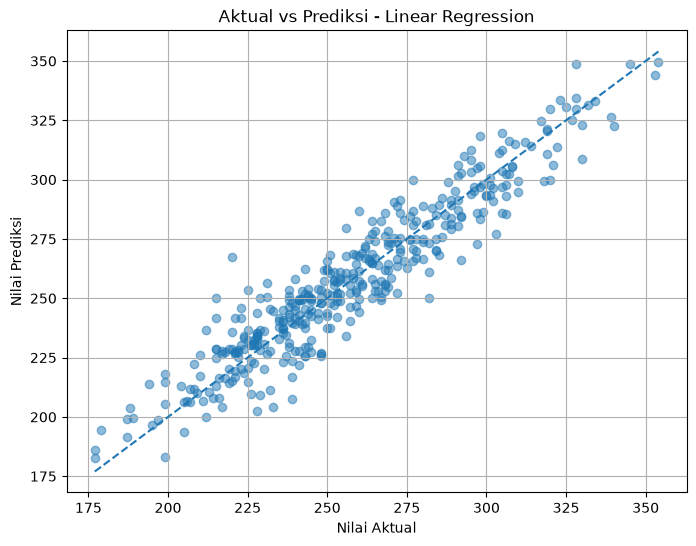

In [47]:
# Visualisasi hasil predic

import matplotlib.pyplot as plt

plt.figure(figsize=(8, 6))

plt.scatter(
    y_test,
    y_pred_linear,
    alpha=0.5
)

min_val = min(y_test.min(), y_pred_linear.min())
max_val = max(y_test.max(), y_pred_linear.max())

plt.plot(
    [min_val, max_val],
    [min_val, max_val],
    linestyle="--"
)

plt.xlabel("Nilai Aktual")
plt.ylabel("Nilai Prediksi")
plt.title("Aktual vs Prediksi - Linear Regression")
plt.grid(True)
plt.show()